## IAFR2302 GULICA ROMAN
# Лабораторная работа №2. Сравнение групп, корреляция и регрессия

## Датасет

Использую открытый датасет **Medical Cost Personal Dataset** (страховые выплаты по клиентам).

Подготовка. Загрузка библиотек и датасета

In [3]:
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")

df = pd.read_csv("insurance.csv")
print(df.shape)
df.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# Задание 1. t-распределение: когда данных мало
Отдел продаж принёс выгрузку всего по 15 курильщикам из нового региона и хочет по ней оценить среднюю выплату. Смоделируем эту ситуацию.

1.1. Сделайте выборку df[df.smoker == "yes"].charges.sample(15, random_state=3). Выведите её среднее и стандартную ошибку (stats.sem).

In [4]:
sample = df[df.smoker == "yes"].charges.sample(15, random_state=3)

sample_mean = sample.mean()

sample_sem = stats.sem(sample)

print("Выборка:")
print(sample)

print("\nРазмер выборки:", len(sample))
print("Средняя выплата:", sample_mean)
print("Стандартная ошибка:", sample_sem)

Выборка:
1085    19023.26000
288     47896.79135
1031    44423.80300
64      14711.74380
98      22412.64850
545     23807.24060
280     22331.56680
123     39556.49450
706     44400.40640
1078    34672.14720
1062    48970.24760
577     58571.07448
1281    24535.69855
1188    21771.34230
259     33750.29180
Name: charges, dtype: float64

Размер выборки: 15
Средняя выплата: 33388.983792
Стандартная ошибка: 3431.8838594056997


1.2. Постройте 95% доверительный интервал для среднего двумя функциями: stats.norm.interval и stats.t.interval (для t укажите df = n - 1). Какой интервал шире? Какой из них правильный в этой ситуации и почему?

In [5]:
norm_interval = stats.norm.interval(
    0.95,
    loc=sample_mean,
    scale=sample_sem
)

t_interval = stats.t.interval(
    0.95,
    df=len(sample) - 1,
    loc=sample_mean,
    scale=sample_sem
)

print("Нормальное распределение:", norm_interval)
print("t-распределение:", t_interval)

print("\nШирина нормального интервала:",
      norm_interval[1] - norm_interval[0])

print("Ширина t-интервала:",
      t_interval[1] - t_interval[0])

Нормальное распределение: (np.float64(26662.615028440505), np.float64(40115.3525555595))
t-распределение: (np.float64(26028.324975869687), np.float64(40749.642608130314))

Ширина нормального интервала: 13452.737527118992
Ширина t-интервала: 14721.317632260627


В ходе проведённого исследования выборки из 15 курильщиков выяснилось что средняя сумма страховых выплат составила 33 388.98 USD, а стандартная ошибка среднего - 3 431.88 USD.

При построении 95% доверительных интервалов с помощью нормального распределения получен интервал от 26 662.62 до 40 115.35 USD, а с помощью t-распределения - от 26 028.32 до 40 749.64 USD.

t-интервал получился шире нормального так как учитывает дополнительную неопределённость, появляющуюся при использовании небольшой выборки. Именно поэтому в данной ситуации правильнее использовать t-распределение.

Для страховой компании это означает, что при оценке средних выплат по небольшому количеству клиентов нужно учитывать повышенную статистическую неопределённость и не делать слишком точных прогнозов на основании ограниченных данных.

# Задание 2. Сравнение двух средних: t-критерий Стьюдента

2.1. Выведите описательную статистику charges по группам smoker (df.groupby("smoker").charges.describe()) и постройте boxplot.

         count          mean           std         min           25%  \
smoker                                                                 
no      1064.0   8434.268298   5993.781819   1121.8739   3986.438700   
yes      274.0  32050.231832  11541.547176  12829.4551  20826.244213   

                50%           75%          max  
smoker                                          
no       7345.40530  11362.887050  36910.60803  
yes     34456.34845  41019.207275  63770.42801  


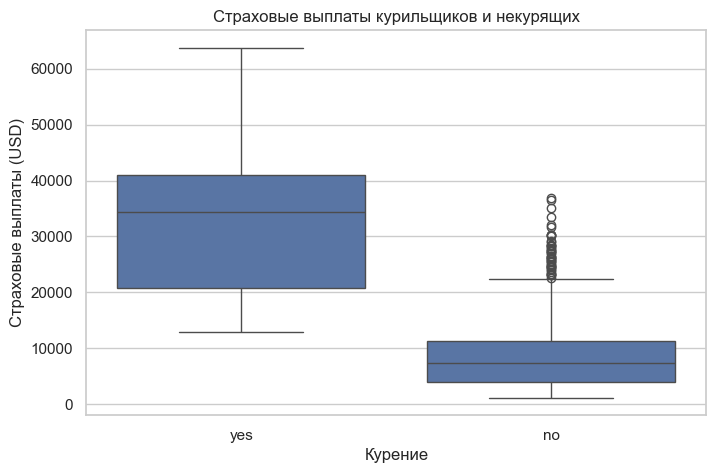

In [6]:
print(df.groupby("smoker").charges.describe())

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="smoker", y="charges")

plt.title("Страховые выплаты курильщиков и некурящих")
plt.xlabel("Курение")
plt.ylabel("Страховые выплаты (USD)")
plt.show()

2.2. Сформулируйте
 и
 и проверьте их функцией stats.ttest_ind(..., equal_var=False). Что означают полученные statistic и pvalue?

In [7]:
smokers = df[df.smoker == "yes"].charges
non_smokers = df[df.smoker == "no"].charges

t_stat, p_value = stats.ttest_ind(
    smokers,
    non_smokers,
    equal_var=False
)

print("t-статистика:", t_stat)
print("p-value:", p_value)

if p_value < 0.05:
    print("Различия статистически значимы")
else:
    print("Статистически значимых различий нет")

t-статистика: 32.751887766341824
p-value: 5.88946444671698e-103
Различия статистически значимы


**Гипотезы:**

- H₀: средние медицинские расходы курильщиков и некурящих одинаковы.
- H₁: средние медицинские расходы курильщиков и некурящих различаются.

**Вывод:** полученное p-value = 5.889 × 10⁻¹⁰³ < 0.05, поэтому отвергаем H₀. Средние медицинские расходы курильщиков и некурящих статистически значимо различаются.

2.3. Проверьте утверждение маркетинга: отличаются ли средние выплаты мужчин и женщин? Затем повторите тот же тест только среди некурящих. Посмотрите на долю курильщиков среди мужчин и женщин (pd.crosstab(df.sex, df.smoker, normalize="index")) и объясните, что произошло (вспомните из лекции про «третью переменную»).

In [8]:
male = df[df.sex == "male"].charges
female = df[df.sex == "female"].charges

t_all = stats.ttest_ind(male, female, equal_var=False)

print("Мужчины и женщины (все клиенты):")
print("t-статистика:", t_all.statistic)
print("p-value:", t_all.pvalue)

male_non_smokers = df[
    (df.sex == "male") & (df.smoker == "no")
].charges

female_non_smokers = df[
    (df.sex == "female") & (df.smoker == "no")
].charges

t_non_smokers = stats.ttest_ind(
    male_non_smokers,
    female_non_smokers,
    equal_var=False
)

print("\nМужчины и женщины (только некурящие):")
print("t-статистика:", t_non_smokers.statistic)
print("p-value:", t_non_smokers.pvalue)

# Доля курильщиков по полу
print("\nДоля курильщиков по полу:")
print(pd.crosstab(df.sex, df.smoker, normalize="index"))

Мужчины и женщины (все клиенты):
t-статистика: 2.1008878232359565
p-value: 0.03584101495601664

Мужчины и женщины (только некурящие):
t-статистика: -1.839622216350089
p-value: 0.06610296328675346

Доля курильщиков по полу:
smoker        no       yes
sex                       
female  0.826284  0.173716
male    0.764793  0.235207


**Гипотезы:**

- H₀: средние медицинские расходы мужчин и женщин одинаковы.
- H₁: средние медицинские расходы мужчин и женщин различаются.

**Вывод:** для всей выборки p-value = 0.03584 < 0.05, поэтому отвергаем H₀. Средние расходы мужчин и женщин статистически значимо различаются.

При повторном сравнении только некурящих p-value = 0.06610 > 0.05, поэтому нет оснований отвергать H₀. Статистически значимых различий среди некурящих не обнаружено.

По итогу сравнения страховых выплат курильщиков и некурящих было обнаружено значительное различие между группами. Средняя выплата курильщикам = 32 050.23 USD, а некурящим = 8 434.27 USD. По результатам t-теста получено p-value = 5.889 × 10⁻¹⁰³, что меньше уровня значимости 0.05. Следовательно, нулевая гипотеза отвергается, а различия являются статистически значимыми.

Сравнение мужчин и женщин среди всех клиентов также обнаружилось статистически значимое различие (p-value = 0.03584). Однако при повторном сравнении только некурящих статистически значимого различия не выявлено (p-value = 0.06610).

Анализ доли курильщиков показал, что среди мужчин курят 23.52%, а среди женщин — 17.37%. Таким образом, курение это третья переменная, которая может объяснять часть различий в страховых выплатах между мужчинами и женщинами.

Для MedGuard это означает, что при формировании страховых тарифов необходимо учитывать статус курения. При этом нельзя утверждать, что пол сам по себе является причиной различий в выплатах на основании проведённого анализа.

# Задание 3. Однофакторный дисперсионный анализ: различаются ли регионы?

3.1. Выведите средние charges по регионам и постройте boxplot charges по region.

region
northeast    13406.384516
northwest    12417.575374
southeast    14735.411438
southwest    12346.937377
Name: charges, dtype: float64


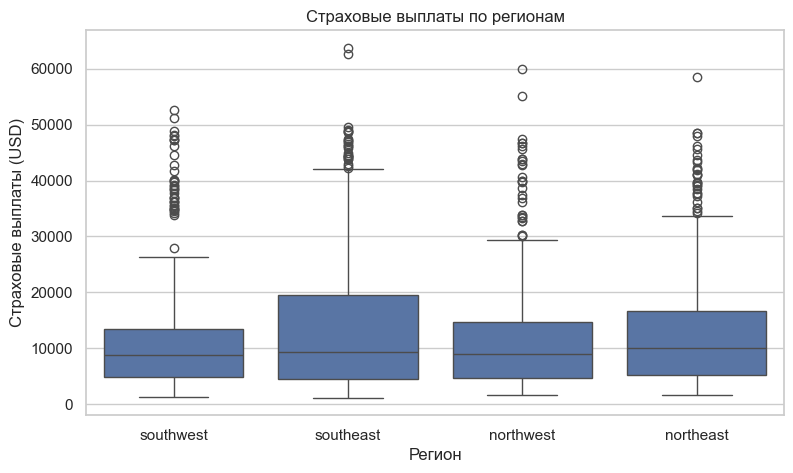

In [9]:
print(df.groupby("region").charges.mean())

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="region",
    y="charges"
)

plt.title("Страховые выплаты по регионам")
plt.xlabel("Регион")
plt.ylabel("Страховые выплаты (USD)")

plt.show()

3.2. Сформулируйте
 и
. Проведите ANOVA двумя способами: stats.f_oneway и таблицей sm.stats.anova_lm(ols("charges ~ C(region)", data=df).fit()). Совпадают ли F и p? Какой вывод?

In [10]:
northeast = df[df.region == "northeast"].charges
northwest = df[df.region == "northwest"].charges
southeast = df[df.region == "southeast"].charges
southwest = df[df.region == "southwest"].charges

anova_result = stats.f_oneway(
    northeast,
    northwest,
    southeast,
    southwest
)

print("ANOVA через stats.f_oneway:")
print("F-статистика:", anova_result.statistic)
print("p-value:", anova_result.pvalue)

model_region = ols(
    "charges ~ C(region)",
    data=df
).fit()

anova_table = sm.stats.anova_lm(
    model_region,
    typ=1
)

print("\nANOVA через statsmodels:")
print(anova_table)

ANOVA через stats.f_oneway:
F-статистика: 2.96962669358912
p-value: 0.0308933560705201

ANOVA через statsmodels:
               df        sum_sq       mean_sq         F    PR(>F)
C(region)     3.0  1.300760e+09  4.335866e+08  2.969627  0.030893
Residual   1334.0  1.947735e+11  1.460071e+08       NaN       NaN


**Гипотезы:**

- H₀: средние медицинские расходы во всех четырёх регионах одинаковы.
- H₁: хотя бы в одном регионе средние медицинские расходы отличаются.

**Вывод:** p-value = 0.03089 < 0.05, поэтому отвергаем H₀. Средние медицинские расходы статистически значимо различаются между регионами. По критерию Тьюки значимое различие обнаружено между регионами Southeast и Southwest.

ANOVA не говорит, какие именно регионы различаются. Примените критерий Тьюки pairwise_tukeyhsd(df.charges, df.region). Какие пары регионов различаются значимо (reject = True)?

In [11]:
tukey_result = pairwise_tukeyhsd(
    endog=df.charges,
    groups=df.region,
    alpha=0.05
)

print(tukey_result)

       Multiple Comparison of Means - Tukey HSD, FWER=0.05       
  group1    group2   meandiff  p-adj    lower      upper   reject
-----------------------------------------------------------------
northeast northwest  -988.8091 0.7245 -3428.9343 1451.3161  False
northeast southeast  1329.0269 0.4745 -1044.9417 3702.9955  False
northeast southwest -1059.4471 0.6792 -3499.5723 1380.6781  False
northwest southeast  2317.8361 0.0583   -54.1994 4689.8716  False
northwest southwest    -70.638 0.9999 -2508.8826 2367.6066  False
southeast southwest -2388.4741 0.0477 -4760.5096  -16.4386   True
-----------------------------------------------------------------


3.4. Проведите ANOVA для bmi по регионам (stats.f_oneway) и сравните средние bmi. Как это может объяснить различия в выплатах?

In [12]:
print("Средний BMI по регионам:")
print(df.groupby("region").bmi.mean())

bmi_result = stats.f_oneway(
    df[df.region == "northeast"].bmi,
    df[df.region == "northwest"].bmi,
    df[df.region == "southeast"].bmi,
    df[df.region == "southwest"].bmi
)

print("\nANOVA для BMI:")
print("F-статистика:", bmi_result.statistic)
print("p-value:", bmi_result.pvalue)

Средний BMI по регионам:
region
northeast    29.173503
northwest    29.199785
southeast    33.355989
southwest    30.596615
Name: bmi, dtype: float64

ANOVA для BMI:
F-статистика: 39.49505720170283
p-value: 1.881838913929143e-24


**Гипотезы:**

- H₀: средний BMI во всех четырёх регионах одинаков.
- H₁: хотя бы в одном регионе средний BMI отличается.

**Вывод:** p-value = 1.8818 × 10⁻²⁴ < 0.05, поэтому отвергаем H₀. Средний BMI статистически значимо различается между регионами. Самое высокое среднее значение BMI наблюдается в регионе Southeast.

В результате анализа средних страховых выплат по регионам было установлено, что наибольшая средняя выплата наблюдается в регионе southeast (14 735.41 USD), а наименьшая - в southwest (12 346.94 USD).

Однофакторный дисперсионный анализ ANOVA, выполненный двумя способами, дал одинаковые результаты: F = 2.969627 и p-value = 0.030893. Поскольку p-value меньше уровня значимости 0.05, нулевая гипотеза отвергается а значит между средними выплатами регионов существуют статистически значимые различия.

По результатам критерия Тьюки статистически значимое различие обнаружено только между регионами southeast и southwest (p-value = 0.0477). Остальные пары регионов не показали статистически значимых различий.

Дополнительно проведён ANOVA для BMI. Результаты показали статистически значимые различия между регионами (F = 39.4951, p-value = 1.8818 × 10⁻²⁴). Наибольшее среднее значение BMI наблюдается в регионе southeast (33.36).

Таким образом, повышенные выплаты в регионе southeast могут быть связаны в том числе с более высоким средним BMI клиентов. Для MedGuard это означает, что при анализе региональных страховых расходов необходимо учитывать не только регион, но и характеристики застрахованных клиентов.

# Задание 4. Корреляция: что связано с выплатами?

4.1. Постройте матрицу корреляций Пирсона для age, bmi, children, charges (df[[...]].corr()) и нарисуйте её тепловой картой (sns.heatmap(..., annot=True)). Какая переменная сильнее всего связана с charges?

               age       bmi  children   charges
age       1.000000  0.109272  0.042469  0.299008
bmi       0.109272  1.000000  0.012759  0.198341
children  0.042469  0.012759  1.000000  0.067998
charges   0.299008  0.198341  0.067998  1.000000


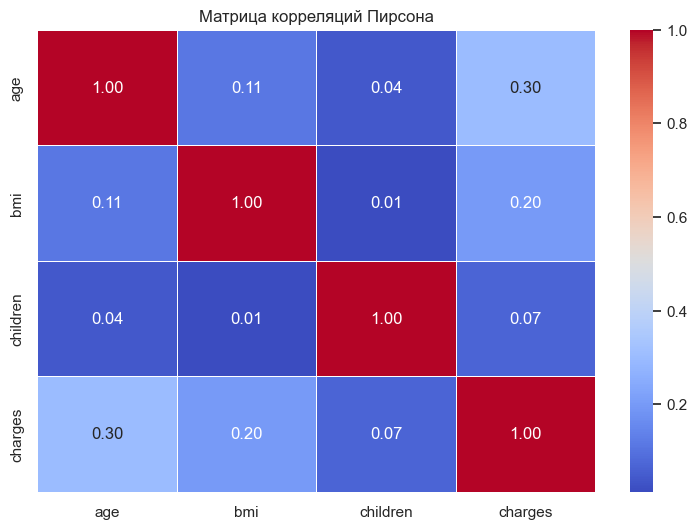

In [13]:
correlation_matrix = df[
    ["age", "bmi", "children", "charges"]
].corr()

print(correlation_matrix)

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Матрица корреляций Пирсона")
plt.show()

4.2. Функцией stats.pearsonr получите коэффициент корреляции между age и charges и его p-значение. Посчитайте коэффициент детерминации
 и объясните его смысл.

In [14]:
correlation, p_value = stats.pearsonr(
    df["age"],
    df["charges"]
)

r_squared = correlation ** 2

print("Коэффициент корреляции:", correlation)
print("p-value:", p_value)
print("Коэффициент детерминации R²:", r_squared)

Коэффициент корреляции: 0.29900819333064743
p-value: 4.886693331718505e-29
Коэффициент детерминации R²: 0.08940589967885783


**Гипотезы:**

- H₀: линейная корреляция между возрастом и медицинскими расходами отсутствует (ρ = 0).
- H₁: линейная корреляция между возрастом и медицинскими расходами существует (ρ ≠ 0).

**Вывод:** коэффициент корреляции r = 0.2990, p-value = 4.8867 × 10⁻²⁹ < 0.05. Отвергаем H₀. Между возрастом и медицинскими расходами существует статистически значимая положительная, но относительно слабая линейная корреляция.

4.3. Постройте диаграмму рассеяния age → charges, раскрасив точки по smoker (sns.scatterplot(..., hue="smoker")). Что видно? Посчитайте stats.pearsonr между age и charges только для некурящих и сравните с общим. Почему перед расчётом корреляции нужно смотреть на график?

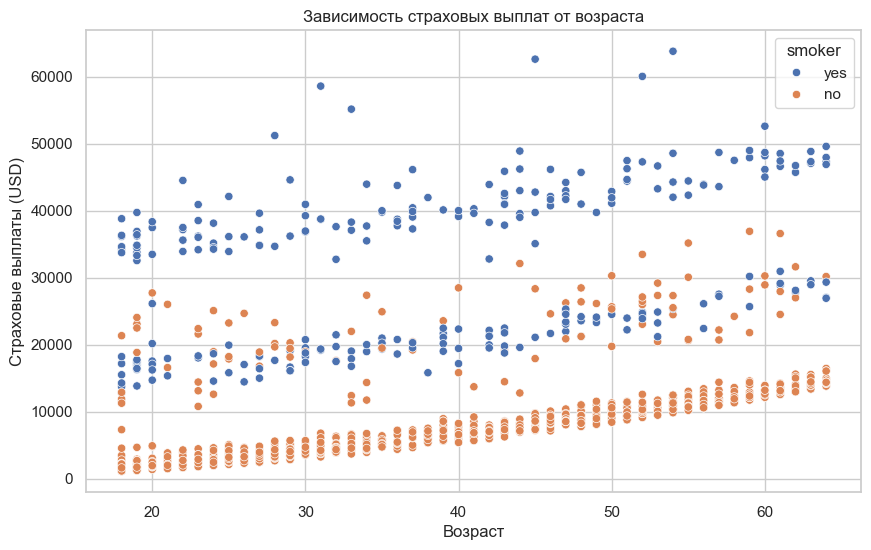

Общая корреляция: 0.29900819333064743
Корреляция среди некурящих: 0.6279467837664197

p-value среди некурящих: 9.172018133370279e-118


In [15]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="age",
    y="charges",
    hue="smoker"
)

plt.title("Зависимость страховых выплат от возраста")
plt.xlabel("Возраст")
plt.ylabel("Страховые выплаты (USD)")
plt.show()

non_smokers_df = df[df["smoker"] == "no"]

correlation_non_smokers, p_value_non_smokers = stats.pearsonr(
    non_smokers_df["age"],
    non_smokers_df["charges"]
)

print("Общая корреляция:", correlation)
print("Корреляция среди некурящих:", correlation_non_smokers)

print("\np-value среди некурящих:", p_value_non_smokers)

**Гипотезы:**

- H₀: среди некурящих линейная корреляция между возрастом и медицинскими расходами отсутствует (ρ = 0).
- H₁: среди некурящих линейная корреляция между возрастом и медицинскими расходами существует (ρ ≠ 0).

**Вывод:** коэффициент корреляции r = 0.6279, p-value = 9.1720 × 10⁻¹¹⁸ < 0.05. Отвергаем H₀. Среди некурящих обнаружена статистически значимая положительная корреляция между возрастом и медицинскими расходами.

В результате анализа корреляционной матрицы выевленно что наиболее сильная связь со страховыми выплатами наблюдается у возраста (r = 0.2990). Корреляция BMI с выплатами составляет 0.1983, а количества детей - 0.0680.

При проверке корреляции между возрастом и страховыми выплатами получено значение r = 0.2990 и p-value = 4.8867 × 10⁻²⁹. Поскольку p-value меньше уровня значимости 0.05, корреляция является статистически значимой.

Коэффициент детерминации R² составил 0.0894, что означает, что линейная зависимость от возраста объясняет около 8.94% изменчивости страховых выплат.

При повторном расчёте корреляции только среди некурящих коэффициент увеличился до 0.6279. Это приводит к более выраженной положительной связи между возрастом и выплатами внутри данной группы.

Диаграмма рассеяния даёт понять различия между курильщиками и некурящими, которые влияют на общую картину корреляции.

Для MedGuard это означает, что возраст является важным фактором анализа выплат, однако для более точного прогнозирования необходимо учитывать и другие характеристики клиентов, особенно статус курения.

# Задание 5. Регрессия с одной независимой переменной

5.1. Постройте модель ols("charges ~ age", data=df).fit() и выведите summary(). Найдите в таблице
 (Intercept),
 (age), их p-значения и
. Запишите уравнение модели и проинтерпретируйте
.

In [16]:
model = ols("charges ~ age", data=df).fit()

print(model.summary())

print("\nКоэффициенты:")
print(model.params)

print("\np-значения:")
print(model.pvalues)

print("\nR²:", model.rsquared)
print("Исправленный R²:", model.rsquared_adj)

                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.089
Model:                            OLS   Adj. R-squared:                  0.089
Method:                 Least Squares   F-statistic:                     131.2
Date:                Sat, 21 Nov 2026   Prob (F-statistic):           4.89e-29
Time:                        20:46:10   Log-Likelihood:                -14415.
No. Observations:                1338   AIC:                         2.883e+04
Df Residuals:                    1336   BIC:                         2.884e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   3165.8850    937.149      3.378      0.0

**Гипотезы:**

- H₀: коэффициент возраста равен нулю (β₁ = 0).
- H₁: коэффициент возраста не равен нулю (β₁ ≠ 0).

**Вывод:** p-value коэффициента age ≈ 4.89 × 10⁻²⁹ < 0.05, поэтому отвергаем H₀. Возраст является статистически значимым предиктором медицинских расходов. Коэффициент положительный, следовательно, с увеличением возраста прогнозируемые расходы возрастают.

5.2. Нарисуйте данные с линией регрессии (sns.regplot(x="age", y="charges", data=df)).

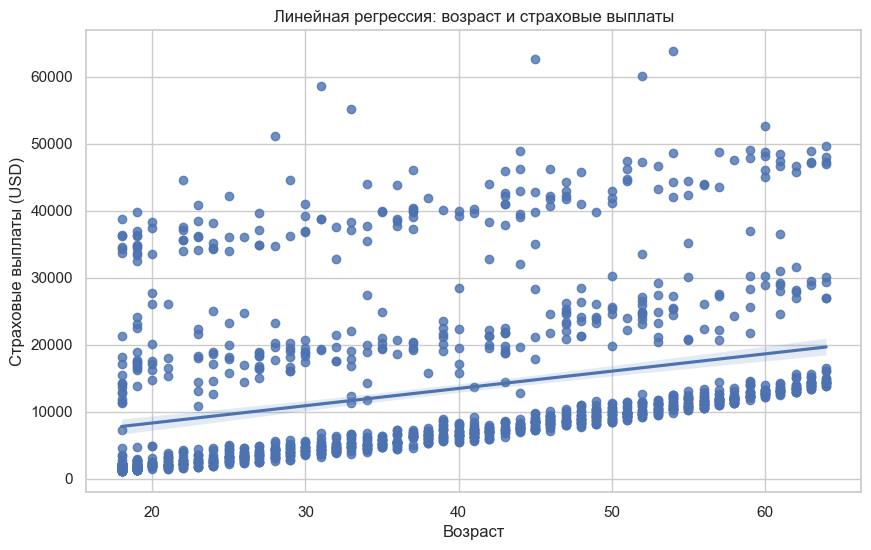

In [17]:
plt.figure(figsize=(10, 6))

sns.regplot(
    x="age",
    y="charges",
    data=df
)

plt.title("Линейная регрессия: возраст и страховые выплаты")
plt.xlabel("Возраст")
plt.ylabel("Страховые выплаты (USD)")

plt.show()

5.3. Методом .predict() найдите прогноз выплаты для клиента 50 лет.

In [18]:
new_client = pd.DataFrame({
    "age": [50]
})

prediction = model.predict(new_client)

print("Прогноз страховой выплаты для клиента 50 лет:")
print(f"{prediction.iloc[0]:.2f} USD")

Прогноз страховой выплаты для клиента 50 лет:
16052.02 USD


5.4. Проверьте условия применения регрессии: постройте график остатков (model.resid) от age и QQ-plot остатков (sm.qqplot(model.resid, line="s")). Выполняются ли нормальность остатков и гомоскедастичность?

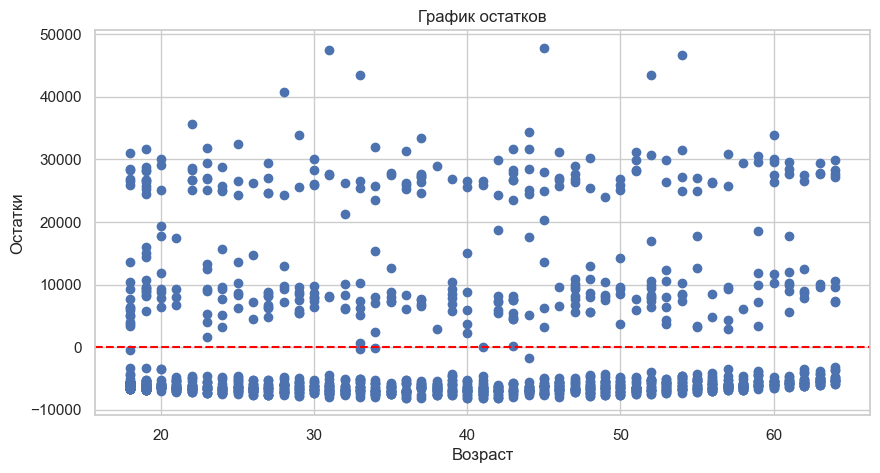

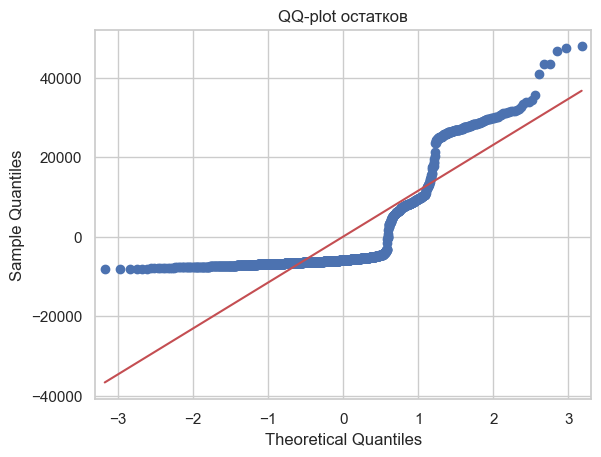

In [19]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df["age"],
    model.resid
)

plt.axhline(y=0, color="red", linestyle="--")

plt.title("График остатков")
plt.xlabel("Возраст")
plt.ylabel("Остатки")

plt.show()


sm.qqplot(
    model.resid,
    line="s"
)

plt.title("QQ-plot остатков")
plt.show()

Построение простой линейной регрессии выявило положительную статистически значимую связь между возрастом клиентов и размером страховых выплат. Полученное уравнение регрессии имеет вид:

**charges = 3165.89 + 257.72 × age.**

Коэффициент при переменной `age` показывает, что при увеличении возраста на один год ожидаемая сумма страховых выплат возрастает в среднем на 257.72 USD. p-value для возраста составляет 4.89 × 10⁻²⁹, что меньше уровня значимости 0.05. Следовательно, возраст является статистически значимым предиктором страховых выплат.

Коэффициент детерминации R² равен 0.0894, то есть модель объясняет только 8.94% изменчивости страховых выплат. Например, для клиента возрастом 50 лет модель прогнозирует выплату в размере 16 052.02 USD.

Анализ графиков показал ограничения модели. На графике остатков наблюдаются выраженные группы точек и неодинаковый разброс, а QQ-график демонстрирует существенное отклонение остатков от нормального распределения. Это указывает на то, что простая линейная модель не полностью описывает особенности данных.

**Вывод:** возраст влияет на прогнозируемый размер страховых выплат, но использовать только возраст для точного прогнозирования недостаточно. Для повышения качества модели необходимо учитывать дополнительные факторы, например BMI, статус курения, количество детей, пол и регион проживания клиента.

# Задание 6. Множественная регрессия и выбор лучшей модели

6.1. Постройте несколько моделей и сравните их по исправленному
 (.rsquared_adj):

In [20]:
formulas = [
    "charges ~ age",
    "charges ~ age + bmi",
    "charges ~ age + bmi + smoker",
    "charges ~ age + bmi + smoker + children",
    "charges ~ age + bmi + smoker + children + sex + region"
]

models = []

for formula in formulas:
    model = ols(formula, data=df).fit()
    models.append(model)

comparison = pd.DataFrame({
    "Модель": [
        "Возраст",
        "Возраст + BMI",
        "Возраст + BMI + Курение",
        "Возраст + BMI + Курение + Дети",
        "Все факторы"
    ],
    "R²": [model.rsquared for model in models],
    "Исправленный R²": [model.rsquared_adj for model in models]
})

print(comparison.to_string(index=False))

                        Модель       R²  Исправленный R²
                       Возраст 0.089406         0.088724
                 Возраст + BMI 0.117183         0.115861
       Возраст + BMI + Курение 0.747477         0.746909
Возраст + BMI + Курение + Дети 0.749695         0.748943
                   Все факторы 0.750913         0.749414


**Гипотезы:**

- H₀: все коэффициенты независимых переменных модели равны нулю.
- H₁: хотя бы один коэффициент независимой переменной не равен нулю.

**Вывод:** общая модель статистически значима, поскольку Prob (F-statistic) < 0.05. Отвергаем H₀. Это означает, что выбранные переменные в совокупности имеют статистически значимую линейную связь с медицинскими расходами.

6.2. Выберите лучшую модель с точки зрения «качество / простота». Выведите её summary() и проинтерпретируйте коэффициенты, особенно при smoker (не забудьте: «при прочих равных»).

In [21]:
best_model = ols(
    "charges ~ age + bmi + smoker + children",
    data=df
).fit()

print(best_model.summary())

print("\nКоэффициенты:")
print(best_model.params)

print("\np-значения:")
print(best_model.pvalues)

print("\nИсправленный R²:", best_model.rsquared_adj)

                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.750
Model:                            OLS   Adj. R-squared:                  0.749
Method:                 Least Squares   F-statistic:                     998.1
Date:                Sat, 21 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:53:54   Log-Likelihood:                -13551.
No. Observations:                1338   AIC:                         2.711e+04
Df Residuals:                    1333   BIC:                         2.714e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept      -1.21e+04    941.984    -12.848

**Гипотезы:**

- H₀: все коэффициенты независимых переменных модели равны нулю.
- H₁: хотя бы один коэффициент независимой переменной не равен нулю.

**Вывод:** общая модель статистически значима, поскольку Prob (F-statistic) < 0.05. Отвергаем H₀. Это означает, что выбранные переменные в совокупности имеют статистически значимую линейную связь с медицинскими расходами.

### Вывод по множественной линейной регрессии

Модель множественной линейной регрессии для прогнозирования страховых выплат на основании возраста клиента, индекса массы тела (BMI), факта курения и количества детей.

Полученная модель имеет коэффициент детерминации R² = 0.750 и исправленный R² = 0.749. Это означает, что выбранные факторы объясняют приблизительно 74.9% изменчивости страховых выплат.

Самая выраженная связь наблюдается у фактора курения: при прочих равных условиях прогнозируемые выплаты курильщикам выше примерно на 23 811.40 USD по сравнению с некурящими клиентами. Также статистически значимыми оказались возраст, BMI и количество детей.

Все рассматриваемые факторы имеют p-value меньше 0.05, поэтому их коэффициенты статистически значимы на уровне значимости 5%.

В сравнении с простой линейной регрессией, учитывающей только возраст, множественная модель показывает значительно более высокое качество. Следовательно, для прогнозирования страховых выплат целесообразно учитывать не только возраст клиента, но и другие характеристики, особенно факт курения.

6.3. В полной модели посмотрите на p-значения (.pvalues) для sex и region. Сравните с выводами заданий 2 и 3.

In [22]:
full_model = ols(
    "charges ~ age + bmi + smoker + children + sex + region",
    data=df
).fit()

print(full_model.summary())

print("\nПроверка значимости пола и региона:")

for factor, p_value in full_model.pvalues.items():
    if "sex" in factor or "region" in factor:
        print(f"{factor}: p-value = {p_value:.6f}")

                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.751
Model:                            OLS   Adj. R-squared:                  0.749
Method:                 Least Squares   F-statistic:                     500.8
Date:                Sat, 21 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:55:32   Log-Likelihood:                -13548.
No. Observations:                1338   AIC:                         2.711e+04
Df Residuals:                    1329   BIC:                         2.716e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept           -1.194e+04    

**Гипотезы:**

- H₀: коэффициент соответствующей переменной (sex или region) равен нулю.
- H₁: коэффициент соответствующей переменной не равен нулю.

**Вывод:** для sex p-value = 0.69335 > 0.05, поэтому нет оснований отвергать H₀. Пол не является статистически значимым предиктором в полной модели.

Для region:
- Northwest: p-value = 0.45877 > 0.05 - нет оснований отвергать H₀.
- Southeast: p-value = 0.03078 < 0.05 - отвергаем H₀.
- Southwest: p-value = 0.04477 < 0.05 - отвергаем H₀.

Таким образом, по сравнению с базовым регионом Northeast статистически значимые различия обнаружены для Southeast и Southwest.

### Вывод по проверке значимости пола и региона

Полная модель множественной линейной регрессии, включающая возраст, BMI, курение, количество детей, пол и регион проживания клиента.

Результаты показали, что пол не является статистически значимым фактором после учёта остальных переменных (p-value = 0.693348). Следовательно, на основании данной модели нельзя утверждать о наличии значимого различия страховых выплат между мужчинами и женщинами.

Для региона получены неодинаковые результаты. Регион Northwest не показал статистически значимого отличия от Northeast (p-value = 0.458769). При этом Southeast (p-value = 0.030782) и Southwest (p-value = 0.044765) имеют статистически значимые отличия от базового региона Northeast.

Добавление пола и региона незначительно увеличило исправленный коэффициент детерминации: с 0.748943 до 0.749414. Поэтому модель с возрастом, BMI, курением и количеством детей остаётся более компактным вариантом с практически таким же качеством прогнозирования.

6.4. По выбранной модели предскажите выплату для двух клиентов 50 лет с bmi = 30: курящего и некурящего.

In [23]:
clients = pd.DataFrame({
    "age": [50, 50],
    "bmi": [30, 30],
    "smoker": ["yes", "no"],
    "children": [0, 0]
})

predictions = best_model.predict(clients)

clients["predicted_charges"] = predictions

print("Прогноз страховых выплат:")
print(clients.to_string(index=False))

difference = predictions.iloc[0] - predictions.iloc[1]

print(f"\nРазница между выплатами: {difference:.2f} USD")

Прогноз страховых выплат:
 age  bmi smoker  children  predicted_charges
  50   30    yes         0       34256.647920
  50   30     no         0       10445.248075

Разница между выплатами: 23811.40 USD


### Вывод по прогнозированию страховых выплат

Используя модели множественной линейной регрессии были рассчитаны прогнозируемые страховые выплаты для двух условных клиентов.

Оба клиента имеют одинаковый возраст (50 лет), индекс массы тела (BMI = 30) и количество детей (0). Единственным различием является статус курения.

Для клиента-курильщика прогнозируемая сумма страховых выплат составила 34 256.65 USD, а для некурящего клиента - 10 445.25 USD.

Разница между прогнозами составила 23 811.40 USD. Это соответствует коэффициенту при переменной курения в построенной регрессионной модели.

Таким образом, модель демонстрирует значительную статистическую связь между курением и размером страховых выплат. Полученные значения являются прогнозами модели, а не гарантированными суммами будущих выплат.